# imports

In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [2]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [3]:
# specific

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

In [4]:
importlib.reload(read_utils)

<module 'utils_fly.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/notebooks/analysis/../../src/utils_fly/read_utils.py'>

# setup

In [5]:
ll = 'll00'
data_variant = 'gcamp'

save = True

In [6]:
# specific

model_variant = 'ns'
organism = 'fly'
manual = True
full = True

In [7]:
file_id = 0

In [8]:
max_noi = 20
neurons_of_interest = ['00_568', '00_521', '00_137', '00_656', '00_601', '00_381', '00_700', '00_426', '00_843']  # , '00_1370'
bhl_selection = ['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move']

# load

In [9]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filename, traces, behavior, classes, timestamps, aux = analysis_utils.read_data(organism, file_id)
metadata = (filename, model_path, model_variant, data_variant, manual, full)

# neuron_labels = analysis_utils.get_significant_neurons(filename, model_variant)[:max_noi]
neuron_labels = []
for neuron in neurons_of_interest:
	if neuron not in neuron_labels and neuron in traces.columns:
		neuron_labels.append(neuron)

# manifold

In [10]:
bom_params, hgm_params = analysis_utils.read_models(*metadata)

((_, bom_man, bom_rec, bom_res, bom_pres, bom_resss, bom_bss),
 (_, hgm_man, hgm_rec, hgm_res, hgm_pres, hgm_resss, hgm_bss)) = analysis_utils.read_predictions(*metadata)

bom_manifolds, bom_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)
hgm_manifolds, hgm_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)

In [11]:
(pca_modes, _, _,
 pca_vars_expl) = train_utils.get_manifolds_pca(
	[traces],
	scale=False, n_pc=hgm_man[0].values.shape[1])
(cca_modes, _, _, _, _, _,
 cca_vars_expl, cca_vars_expl_rs) = train_utils.get_manifolds_cca(
	[traces], [classes[bhl_selection]],
	scale=False, n_cv=min(hgm_man[0].values.shape[1], classes[bhl_selection].values.shape[1]), n_pc=classes[bhl_selection].values.shape[1])
(plsc_modes, _, _, _, _, _,
 plsc_vars_expl) = train_utils.get_manifolds_plsc(
	[traces], [classes[bhl_selection]],
	scale=False, n_ls=min(hgm_man[0].values.shape[1], classes[bhl_selection].values.shape[1]))

In [12]:
# if organism == 'mouse':
# 	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(len(bom_manifolds))],
# 						  [bom_manifolds[s] for s in range(len(bom_manifolds))],
# 						  [aux[0][['running_speed']] for s in range(len(bom_manifolds))],
# 						  bom_manifold_vars_expl, None,
# 						  title='bom manifold', plots_per_row=len(bom_manifolds), top_space=0.5,
# 						  save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_bom_states' if save else None)
#
# else:
# 	plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(bom_manifolds))],
# 							  [bom_manifolds[s] for s in range(len(bom_manifolds))],
# 							  [classes for s in range(len(bom_manifolds))],
# 							  bom_manifold_vars_expl, None,
# 							  title='bom manifold', plots_per_row=len(bom_manifolds), top_space=3.5,
# 							  save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_bom_states' if save else None)

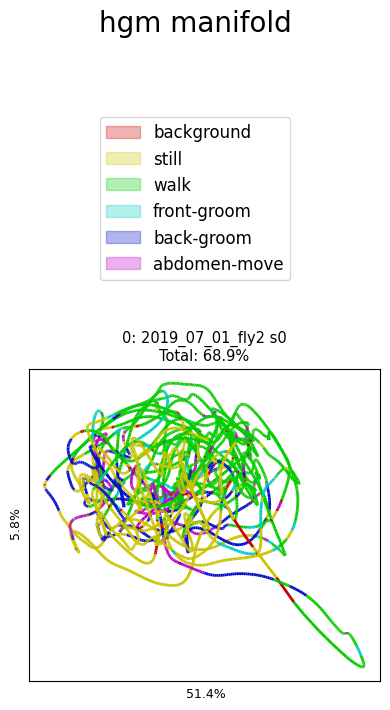

68.9%


In [13]:
if organism == 'mouse':
	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(len(hgm_manifolds))],
						  [hgm_manifolds[s] for s in range(len(hgm_manifolds))],
						  [aux[0][['running_speed']] for s in range(len(hgm_manifolds))],
						  hgm_manifold_vars_expl, None,
						  title='hgm manifold', plots_per_row=len(hgm_manifolds), top_space=0.5,
						  save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_hgm_states' if save else None)

else:
	plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(hgm_manifolds))],
							  [hgm_manifolds[s] for s in range(len(hgm_manifolds))],
							  [classes for s in range(len(hgm_manifolds))],
							  hgm_manifold_vars_expl, None,
							  title='hgm manifold', plots_per_row=len(hgm_manifolds), top_space=3.5,
							  save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_hgm_states' if save else None)

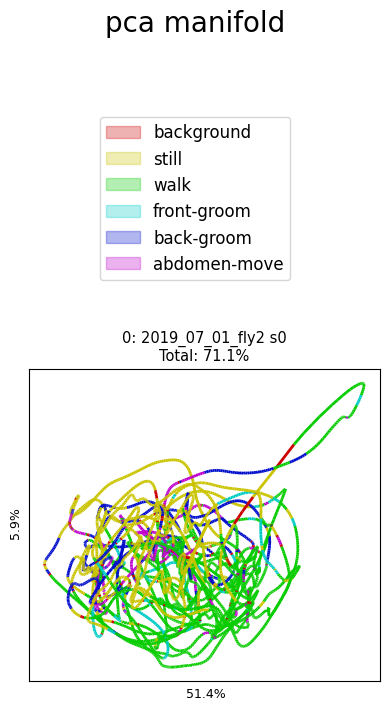

71.1%


In [14]:
if organism == 'mouse':
	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(len(pca_modes))],
						  [pca_modes[s] for s in range(len(pca_modes))],
						  [aux[0][['running_speed']] for s in range(len(pca_modes))],
						  pca_vars_expl, None,
						  title='pca manifold', plots_per_row=len(pca_modes), top_space=0.5,
						  save_path=f'../../out/plots/manifolds/{filename}/pca_states' if save else None)

else:
	plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(pca_modes))],
							  [pca_modes[s] for s in range(len(pca_modes))],
							  [classes for s in range(len(pca_modes))],
							  pca_vars_expl, None,
							  title='pca manifold', plots_per_row=len(pca_modes), top_space=3.5,
							  save_path=f'../../out/plots/manifolds/{filename}/pca_states' if save else None)

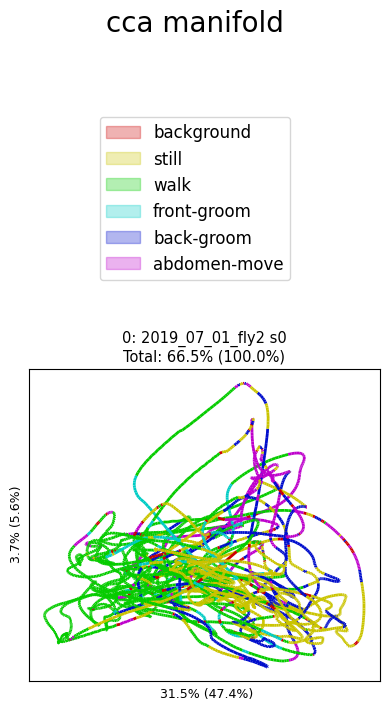

66.5% (100.0%)


In [15]:
if organism == 'mouse':
	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(len(cca_modes))],
						  [cca_modes[s] for s in range(len(cca_modes))],
						  [aux[0][['running_speed']] for s in range(len(cca_modes))],
						  cca_vars_expl, cca_vars_expl_rs,
						  title='cca manifold', plots_per_row=len(cca_modes), top_space=0.5,
						  save_path=f'../../out/plots/manifolds/{filename}/cca_states' if save else None)

else:
	plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(cca_modes))],
							  [cca_modes[s] for s in range(len(cca_modes))],
							  [classes for s in range(len(cca_modes))],
							  cca_vars_expl, cca_vars_expl_rs,
							  title='cca manifold', plots_per_row=len(cca_modes), top_space=3.5,
							  save_path=f'../../out/plots/manifolds/{filename}/cca_states' if save else None)

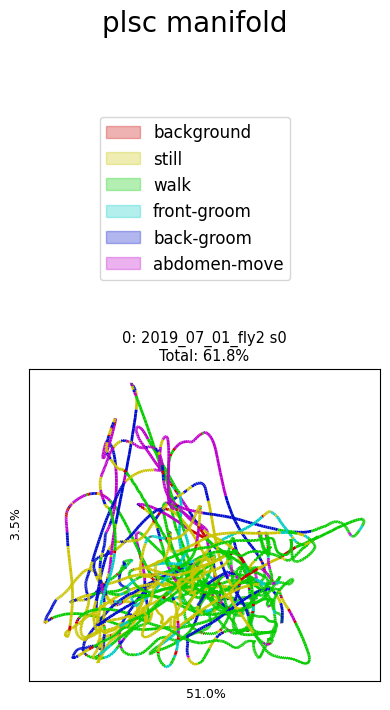

61.8%


In [16]:
if organism == 'mouse':
	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(len(plsc_modes))],
						  [plsc_modes[s] for s in range(len(plsc_modes))],
						  [aux[0][['running_speed']] for s in range(len(plsc_modes))],
						  plsc_vars_expl, None,
						  title='plsc manifold', plots_per_row=len(plsc_modes), top_space=0.5,
						  save_path=f'../../out/plots/manifolds/{filename}/plsc_states' if save else None)

else:
	plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(plsc_modes))],
							  [plsc_modes[s] for s in range(len(plsc_modes))],
							  [classes for s in range(len(plsc_modes))],
							  plsc_vars_expl, None,
							  title='plsc manifold', plots_per_row=len(plsc_modes), top_space=3.5,
							  save_path=f'../../out/plots/manifolds/{filename}/plsc_states' if save else None)

# manifold by gating

In [17]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))
neuron_ids = [traces.columns.get_loc(neuron) for neuron in neuron_labels]

In [18]:
hgm_man_zs = [(hgm_man[s].values - hgm_man[s].values.mean(axis=0)) / np.where((N_std := hgm_man[s].values.std(axis=0)) == 0.0, 1.0, N_std) for s in range(len(hgm_man))]
WMs = [hgm_params[s]['model']['WM'] for s in range(len(hgm_params))]
gating_term = [pd.DataFrame(sigmoid(hgm_man_zs[s] @ WMs[s]), columns=traces.columns) for s in range(len(hgm_man_zs))]

In [19]:
# plot_utils.plot_manifolds_gradient([f'{label}' for label in neuron_labels],
# 								   [bom_manifolds[0]] * len(neuron_ids),
# 								   [gating_term[0].iloc[:, n_id] for n_id in neuron_ids],
# 								   bom_manifold_vars_expl * len(neuron_ids), None,
# 								   title=f'{str(file_id)}: {filename} gcamp bom manifolds by gating of the different neurons',
# 								   plots_per_row=3, top_space=1,
# 								   save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_bom_gating' if save else None)

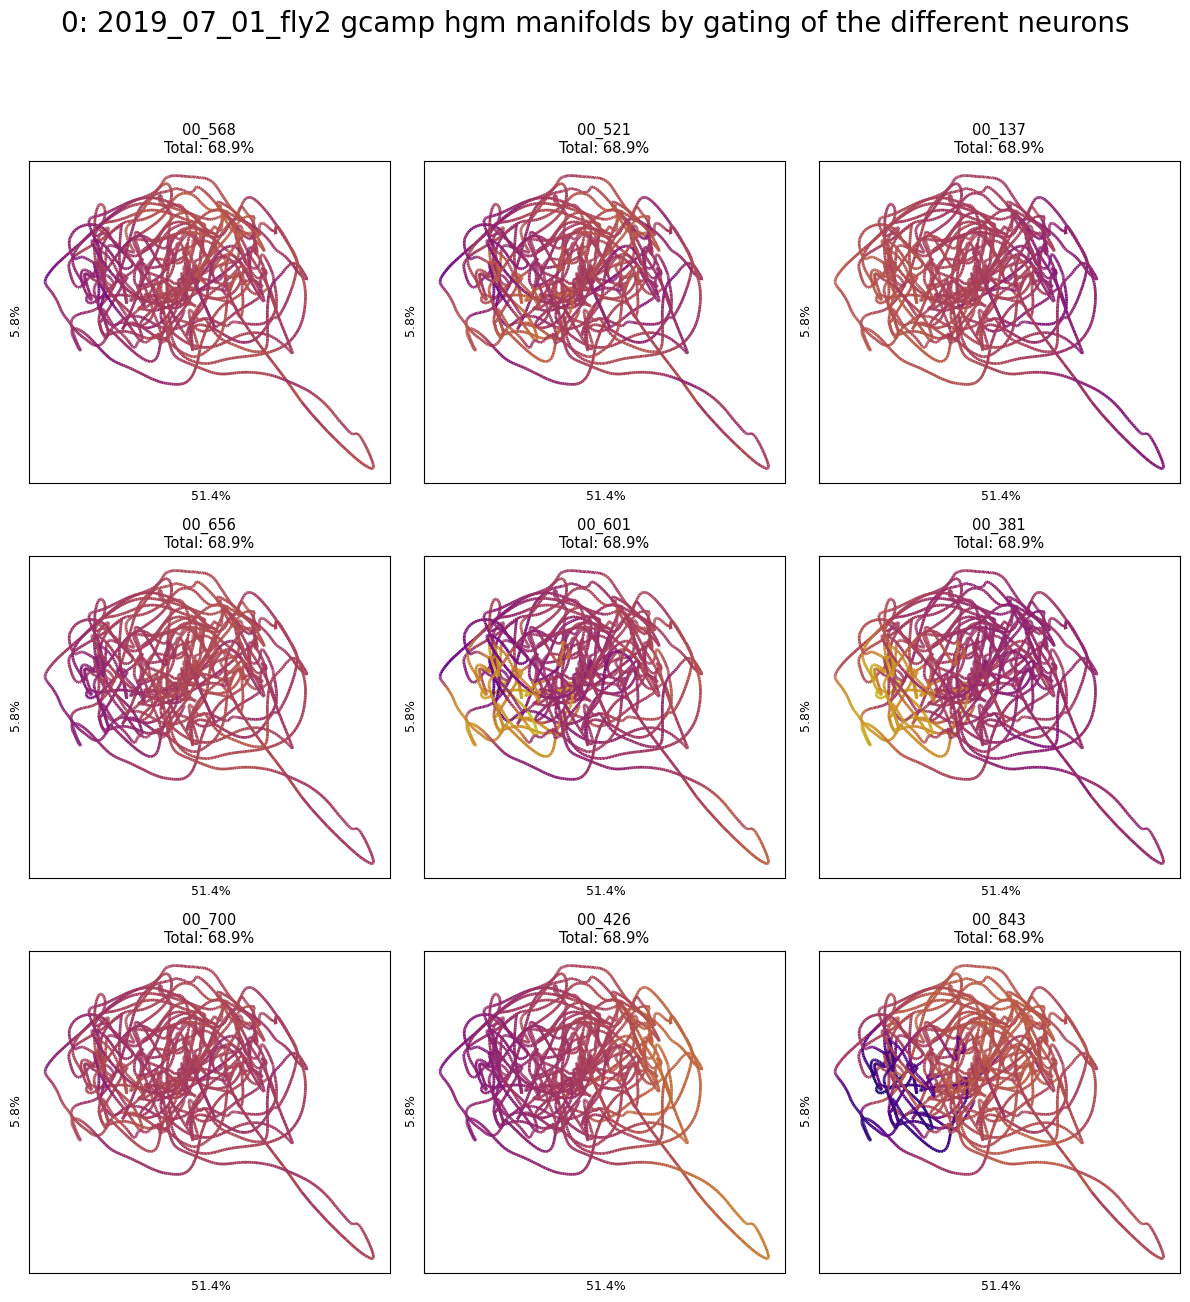

68.9%


In [20]:
plot_utils.plot_manifolds_gradient([f'{label}' for label in neuron_labels],
								   [hgm_manifolds[0]] * len(neuron_ids),
								   [gating_term[0].iloc[:, n_id] for n_id in neuron_ids],
								   hgm_manifold_vars_expl * len(neuron_ids), None,
								   title=f'{str(file_id)}: {filename} gcamp hgm manifolds by gating of the different neurons',
								   plots_per_row=3, top_space=1,
								   save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_hgm_gating' if save else None)

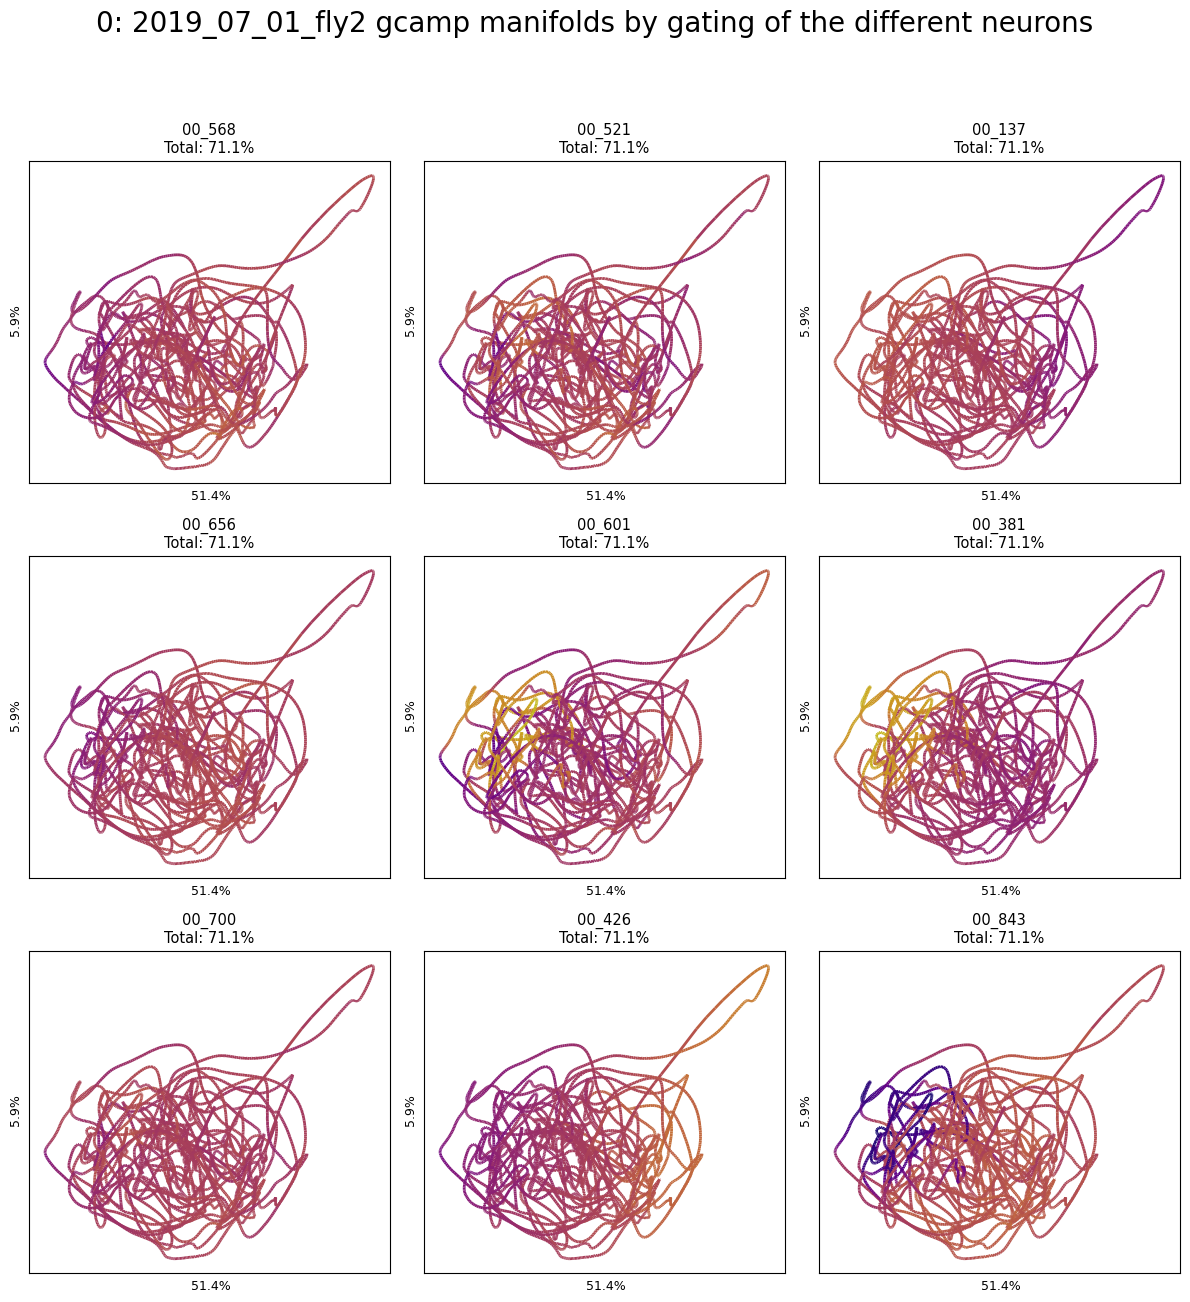

71.1%


In [21]:
plot_utils.plot_manifolds_gradient([f'{label}' for label in neuron_labels],
								   [pca_modes[0]] * len(neuron_ids),
								   [gating_term[0].iloc[:, n_id] for n_id in neuron_ids],
								   pca_vars_expl * len(neuron_ids), None,
								   title=f'{str(file_id)}: {filename} gcamp manifolds by gating of the different neurons',
								   plots_per_row=3, top_space=1,
								   save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_pca_gating' if save else None)

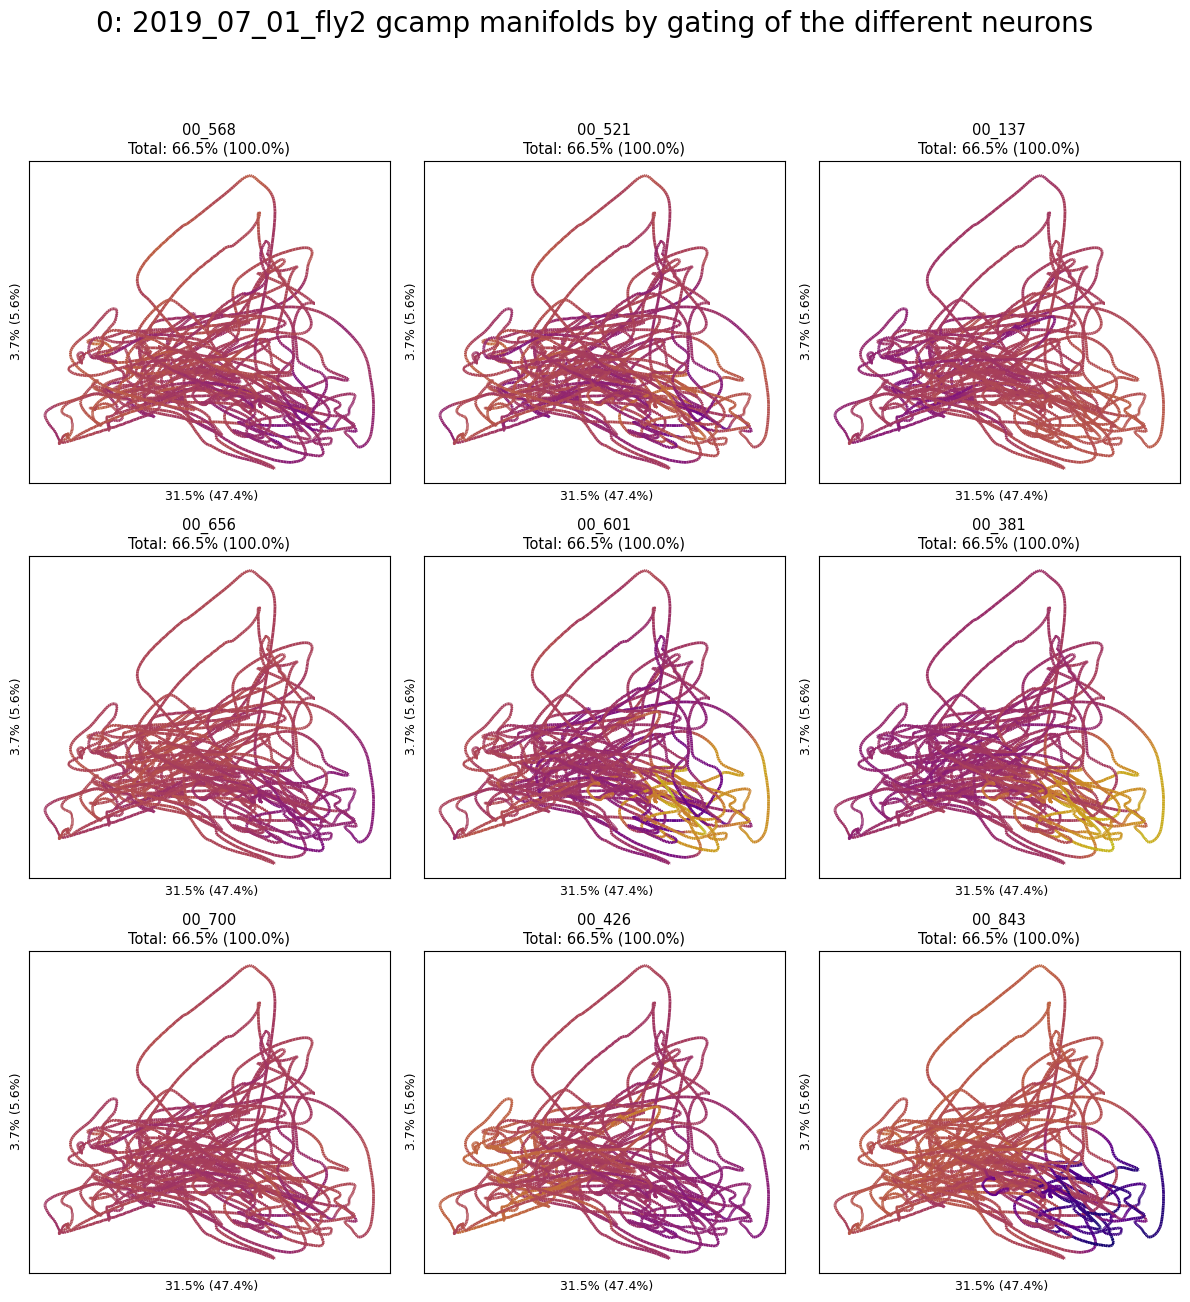

66.5% (100.0%)


In [22]:
plot_utils.plot_manifolds_gradient([f'{label}' for label in neuron_labels],
								   [cca_modes[0]] * len(neuron_ids),
								   [gating_term[0].iloc[:, n_id] for n_id in neuron_ids],
								   cca_vars_expl * len(neuron_ids), cca_vars_expl_rs * len(neuron_ids),
								   title=f'{str(file_id)}: {filename} gcamp manifolds by gating of the different neurons',
								   plots_per_row=3, top_space=1,
								   save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_cca_gating' if save else None)

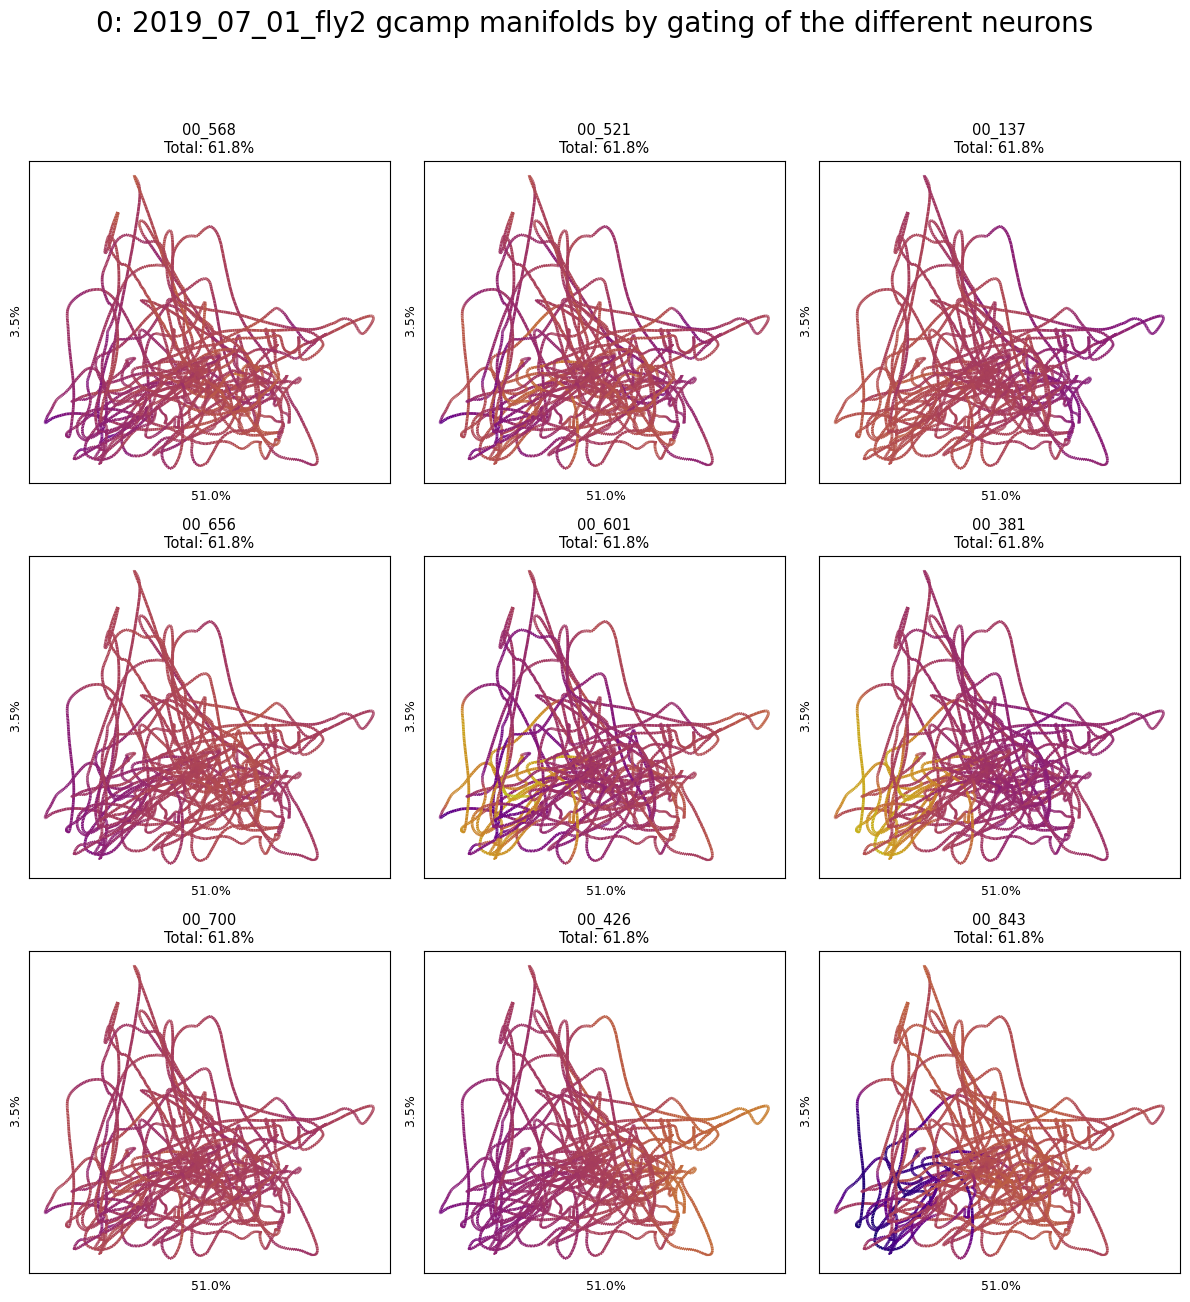

61.8%


In [23]:
plot_utils.plot_manifolds_gradient([f'{label}' for label in neuron_labels],
								   [plsc_modes[0]] * len(neuron_ids),
								   [gating_term[0].iloc[:, n_id] for n_id in neuron_ids],
								   plsc_vars_expl * len(neuron_ids), None,
								   title=f'{str(file_id)}: {filename} gcamp manifolds by gating of the different neurons',
								   plots_per_row=3, top_space=1,
								   save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_plsc_gating' if save else None)